# Siting a Community Cold Store for Hathras Potato Farmers
### A p-Median spatial optimisation tool for a multi-purpose farmers' cooperative

**What this notebook does:** given where smallholder potato clusters are and how much each one harvests, it picks the candidate site for a **cooperative-owned cold storage facility** that minimises the total haulage burden on farmers (in **ton-kilometres**). It then compares that site against the status quo of hauling to a private storage hub.

| Section | Contents |
|---|---|
| 1 | Economic context and the location-theory model behind the tool |
| 2 | Environment setup |
| 3 | Synthetic but realistic data for Hathras district |
| 4 | Mixed-integer p-Median model solved with PuLP / CBC |
| 5 | Map, baseline-vs-optimised report, sensitivity checks |

> **Data disclaimer.** All farmer clusters, harvest volumes, candidate sites and the private-storage hub are **synthetic** and generated with a fixed random seed. They are bounded by Hathras coordinates so the geometry is realistic, but they do not represent real villages, firms or households. Replace Section 3 with field-survey data before using the results for a real decision.

---
## 1. Introduction & Economic Context

### 1.1 The Hathras potato supply chain
Hathras, in western Uttar Pradesh, sits in the Agra–Aligarh potato belt, one of India's most concentrated potato-growing regions. The crop is harvested in a short window (roughly February–March). Because potatoes are perishable and temperature-sensitive, most of the harvest must go into **cold storage within days** and is released gradually over the following months as prices recover.

That timing problem gives whoever controls storage and transport a lot of leverage. The cooperative proposal this tool supports identifies three linked frictions:

| Friction | Mechanism | Effect on the farmer |
|---|---|---|
| **Logistical limitations** | Fragmented landholdings produce small lots. Moving a few tonnes by tractor-trolley costs far more per ton-km than a full truck, and remote clusters face long hauls. | High transport cost per ton. Many sell locally at harvest-time prices instead of storing. |
| **Capital scarcity** | No working capital for seed, fertiliser and pesticide, so farmers borrow from traders or cold-storage owners at high interest. | Debt ties the farmer to the lender's storage and buying terms. |
| **Private cold-storage power** | A few private operators control capacity near the town. They set rents and often double as buyers or lenders. | High rents, forced or distressed sales, and price manipulation at release time. |

These frictions reinforce each other. Distance to storage raises costs, high costs push farmers toward credit, and credit ties them to the storage operator.

### 1.2 The intervention: a community-run cold store
A **multi-purpose cooperative** (credit + marketing) can pool produce and capital to build or lease its own storage. Where that facility is placed matters a great deal. One badly placed store just recreates the distance penalty. A well-placed one cuts haulage for every member every season, and the saving recurs for the life of the asset.

### 1.3 Location theory: from Weber to the p-Median
The **Weber problem** (Alfred Weber, 1909) asks where to put one facility in continuous space so that the demand-weighted sum of distances to it is as small as possible. In practice a cooperative cannot build anywhere. It is limited to a short list of **candidate sites** where land, road access, grid power and legal clearance are available.

That turns the problem into the **discrete p-Median problem** (Hakimi, 1964; ReVelle & Swain, 1970): choose *p* of the candidate sites and assign each demand point to one open site, minimising

$$
\min \; Z = \sum_{i \in I}\sum_{j \in J} w_i \, d_{ij} \, x_{ij}
$$

subject to

$$
\begin{aligned}
\sum_{j \in J} x_{ij} &= 1 && \forall i \in I \quad &&\text{(every cluster is served exactly once)}\\
x_{ij} &\le y_j && \forall i, j &&\text{(only by an open facility)}\\
\sum_{j \in J} y_j &= p && &&\text{(open exactly } p \text{ facilities)}\\
x_{ij},\, y_j &\in \{0,1\}
\end{aligned}
$$

| Symbol | Meaning |
|---|---|
| $I$ | farmer clusters (demand points), $\lvert I\rvert = 50$ |
| $J$ | candidate cold-storage sites, $\lvert J\rvert = 5$ |
| $w_i$ | harvest volume of cluster $i$ (tons) |
| $d_{ij}$ | road distance from cluster $i$ to site $j$ (km) |
| $y_j$ | 1 if site $j$ is opened |
| $x_{ij}$ | 1 if cluster $i$ is assigned to site $j$ |

The objective $Z$ is measured in **ton-km**, which converts directly into rupees through a freight rate. For the cooperative's first facility we set **p = 1**. Section 5.4 shows what a second or third facility would add.

---
## 2. Dependencies & Environment Setup
Install with `pip install -r requirements.txt`. PuLP bundles the open-source **CBC** solver, but that binary is Intel-only on macOS. The notebook therefore prefers **HiGHS** (`highspy`, native wheels on every platform) and falls back to CBC automatically.

In [1]:
# --- Core scientific stack -------------------------------------------------
import numpy as np
import pandas as pd

# --- Geospatial ------------------------------------------------------------
import geopandas as gpd
from shapely.geometry import Point, LineString, box

# --- Optimisation ----------------------------------------------------------
import pulp

# --- Visualisation ---------------------------------------------------------
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# --- Utilities -------------------------------------------------------------
from itertools import combinations
from pathlib import Path

pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.width", 120)

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

print(f"geopandas {gpd.__version__} | pulp {pulp.__version__} | pandas {pd.__version__} | numpy {np.__version__}")
print("Available MILP solvers:", pulp.listSolvers(onlyAvailable=True))


def get_solver(verbose: bool = False):
    # Pick a working MILP solver. PuLP's bundled CBC binary is x86-64 only on macOS,
    # so on Apple Silicon without Rosetta it fails to launch; HiGHS (pip install highspy)
    # ships native wheels for every platform. Try HiGHS first, then CBC.
    probe = pulp.LpProblem("probe", pulp.LpMinimize)
    v = pulp.LpVariable("v", 0, 1, cat=pulp.LpBinary)
    probe += v
    for factory in (lambda: pulp.HiGHS(msg=verbose), lambda: pulp.PULP_CBC_CMD(msg=verbose)):
        try:
            solver = factory()
            if solver.available() and probe.solve(solver) == pulp.LpStatusOptimal:
                return solver
        except Exception:
            continue
    raise RuntimeError("No working MILP solver found. Run: pip install highspy")


SOLVER = get_solver()
print("Using solver:", SOLVER.name)

geopandas 1.0.1 | pulp 3.3.1 | pandas 2.3.3 | numpy 2.0.2
Available MILP solvers: ['PULP_CBC_CMD', 'HiGHS']
Using solver: HiGHS


### 2.1 Model parameters
All assumptions are collected in one cell so they are easy to audit and change. The rupee figures are **illustrative planning values**, not quotes. Replace them with local freight rates when you have them.

In [2]:
# ===================== STUDY AREA ==========================================
LON_MIN, LON_MAX = 78.0, 78.3          # Hathras bounding box (degrees E)
LAT_MIN, LAT_MAX = 27.5, 27.8          # Hathras bounding box (degrees N)
CRS_GEO   = "EPSG:4326"                # WGS-84 lon/lat
CRS_METRIC = "EPSG:32644"              # UTM zone 44N: metres, valid for 78–84°E

# ===================== SIMULATION ==========================================
RANDOM_SEED     = 42
N_CLUSTERS      = 50                   # smallholder farmer clusters
N_CANDIDATES    = 5                    # candidate cooperative cold-store sites

# A "cluster" = a hamlet-level group of smallholders pooling their harvest.
FARMERS_PER_CLUSTER = (8, 30)          # uniform range (households)
LANDHOLDING_HA      = (0.3, 0.8, 2.0)  # triangular (min, mode, max) potato area per household, ha
POTATO_YIELD_T_HA   = (22, 30)         # uniform range, t/ha (typical UP potato belt yields)

# ===================== LOGISTICS ===========================================
ROAD_CIRCUITY   = 1.30                 # road km per straight-line km (rural network detour factor)
FREIGHT_INR_PER_TKM = 12.0             # illustrative small-lot tractor-trolley rate, ₹ per ton-km

# ===================== MODEL ===============================================
P_FACILITIES    = 1                    # open exactly one community facility

rng = np.random.default_rng(RANDOM_SEED)

---
## 3. Realistic Synthetic Data Generation

### 3.1 Farmer clusters
Real settlement patterns are clumpy, not uniform. Villages group along roads and near water. To reflect that, the generator mixes two processes:

* **70 % of clusters** are scattered around a few **settlement hotspots** (Gaussian spread around hotspot centres).
* **30 %** are scattered uniformly to represent outlying hamlets.

Every point is clipped to the bounding box, so the simulation stays strictly inside Hathras coordinates.

**Harvest volume** is built bottom-up instead of drawn as one arbitrary number:

$$\text{volume}_i = \sum_{h=1}^{n_i} \text{area}_h \times \text{yield}_i$$

Here $n_i$ is the number of households, each household farms a small triangular-distributed area (mode 0.8 ha), and yield varies by cluster. The result is a right-skewed spread of small lots, which is what fragmented landholdings produce.

In [3]:
def generate_farmer_clusters(n: int, rng: np.random.Generator) -> gpd.GeoDataFrame:
    # Generate n smallholder clusters inside the Hathras bounding box.
    # Returns a GeoDataFrame (EPSG:4326) with households, area, yield and volume.

    # --- Spatial pattern: hotspots + uniform background ---------------------
    n_hot = int(round(0.7 * n))
    hotspots = np.column_stack([
        rng.uniform(LON_MIN + 0.04, LON_MAX - 0.04, size=4),
        rng.uniform(LAT_MIN + 0.04, LAT_MAX - 0.04, size=4),
    ])
    which = rng.integers(0, len(hotspots), size=n_hot)
    hot_pts = hotspots[which] + rng.normal(0, 0.035, size=(n_hot, 2))
    bg_pts = np.column_stack([
        rng.uniform(LON_MIN, LON_MAX, size=n - n_hot),
        rng.uniform(LAT_MIN, LAT_MAX, size=n - n_hot),
    ])
    pts = np.vstack([hot_pts, bg_pts])
    pts[:, 0] = np.clip(pts[:, 0], LON_MIN + 0.005, LON_MAX - 0.005)   # strict containment
    pts[:, 1] = np.clip(pts[:, 1], LAT_MIN + 0.005, LAT_MAX - 0.005)

    # --- Production: households x landholding x yield ----------------------
    households = rng.integers(FARMERS_PER_CLUSTER[0], FARMERS_PER_CLUSTER[1] + 1, size=n)
    area_ha = np.array([rng.triangular(*LANDHOLDING_HA, size=h).sum() for h in households])
    yield_t_ha = rng.uniform(*POTATO_YIELD_T_HA, size=n)
    volume_t = area_ha * yield_t_ha

    df = pd.DataFrame({
        "cluster_id": [f"F{i+1:02d}" for i in range(n)],
        "lon": pts[:, 0], "lat": pts[:, 1],
        "households": households,
        "potato_area_ha": area_ha,
        "yield_t_ha": yield_t_ha,
        "volume_t": volume_t.round(1),
    })
    df["avg_lot_t"] = df["volume_t"] / df["households"]       # per-household lot size
    return gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.lon, df.lat), crs=CRS_GEO)


farmers = generate_farmer_clusters(N_CLUSTERS, rng)
farmers.drop(columns="geometry").describe().T[["mean", "min", "50%", "max"]]

,mean,min,50%,max
lon,78.18,78.03,78.19,78.29
lat,27.68,27.51,27.71,27.76
households,18.54,8.00,18.50,30.00
potato_area_ha,19.19,7.91,19.01,32.22
yield_t_ha,26.33,22.06,26.55,29.99
volume_t,505.46,199.80,501.50,891.70
avg_lot_t,27.16,20.23,26.80,35.22


Each household harvests roughly 20–35 t. A tractor-trolley carries about 5–8 t, so that harvest leaves the field as **many small, separate trips** rather than a few consolidated truckloads. That is the **fragmentation problem** in numbers: without aggregation, every ton moves at small-load freight rates, and every extra kilometre to storage is paid for again on each trip.

### 3.2 Candidate cooperative sites and the status-quo baseline
**Candidate sites** stand in for parcels the cooperative could actually acquire (panchayat land, a disused warehouse, a plot on a metalled road with three-phase power). They are spread across the district on a jittered grid so the solver has real alternatives to compare.

**Baseline.** To measure what the cooperative gains, we also need the status quo. We model it as a **single private cold-storage hub** in the south-west near the district town, where private capacity tends to concentrate. Every farmer is assumed to haul there today. This is a synthetic stand-in, not a specific facility.

In [4]:
def generate_candidate_sites(n: int, rng: np.random.Generator) -> gpd.GeoDataFrame:
    # Place n candidate sites on a jittered spread across the study area.
    anchors = np.array([          # rough positions as fractions of the bbox (lon, lat)
        [0.25, 0.25], [0.75, 0.30], [0.50, 0.55], [0.25, 0.80], [0.78, 0.78],
    ])[:n]
    jitter = rng.uniform(-0.06, 0.06, size=anchors.shape)
    frac = np.clip(anchors + jitter, 0.05, 0.95)
    lon = LON_MIN + frac[:, 0] * (LON_MAX - LON_MIN)
    lat = LAT_MIN + frac[:, 1] * (LAT_MAX - LAT_MIN)
    df = pd.DataFrame({
        "site_id": [f"C{j+1}" for j in range(n)],
        "lon": lon, "lat": lat,
    })
    return gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.lon, df.lat), crs=CRS_GEO)


candidates = generate_candidate_sites(N_CANDIDATES, rng)

# Status-quo: one private storage hub near the district town (synthetic).
private_hub = gpd.GeoDataFrame(
    {"site_id": ["PRIVATE_HUB"], "lon": [78.05], "lat": [27.59]},
    geometry=[Point(78.05, 27.59)], crs=CRS_GEO,
)

# Sanity check: everything sits strictly inside the Hathras box.
study_area = gpd.GeoDataFrame(geometry=[box(LON_MIN, LAT_MIN, LON_MAX, LAT_MAX)], crs=CRS_GEO)
for name, g in [("farmers", farmers), ("candidates", candidates), ("private_hub", private_hub)]:
    assert g.within(study_area.geometry.iloc[0]).all(), f"{name} outside study area"
print(f"{len(farmers)} clusters | {farmers.volume_t.sum():,.0f} t total harvest | {farmers.households.sum()} households")
candidates.drop(columns="geometry")

50 clusters | 25,273 t total harvest | 927 households


,site_id,lon,lat
0,C1,78.09,27.58
1,C2,78.21,27.60
2,C3,78.17,27.66
3,C4,78.07,27.74
4,C5,78.22,27.74


### 3.3 Distance matrix
Distances are computed in a **metric projection** (UTM 44N) rather than from raw degrees. At 27.6° N one degree of longitude is about 99 km while one degree of latitude is about 111 km, so Euclidean distance on degrees would bias the result. The straight-line distance is then multiplied by a **road circuity factor** (1.3) to approximate travel on the rural road network.

> **Production upgrade:** swap `build_distance_matrix` for real network distances from OpenStreetMap (e.g. `osmnx` + `networkx` shortest paths) or a routing engine such as OSRM. Nothing else in the notebook needs to change.

In [5]:
def build_distance_matrix(origins: gpd.GeoDataFrame, dests: gpd.GeoDataFrame,
                          circuity: float = ROAD_CIRCUITY) -> np.ndarray:
    # Return an |origins| x |dests| matrix of estimated road distance in km.
    o = origins.to_crs(CRS_METRIC).geometry
    d = dests.to_crs(CRS_METRIC).geometry
    ox, oy = o.x.to_numpy()[:, None], o.y.to_numpy()[:, None]
    dx, dy = d.x.to_numpy()[None, :], d.y.to_numpy()[None, :]
    straight_km = np.hypot(ox - dx, oy - dy) / 1000.0
    return straight_km * circuity


D = build_distance_matrix(farmers, candidates)              # 50 x 5
D_hub = build_distance_matrix(farmers, private_hub)[:, 0]   # 50
w = farmers["volume_t"].to_numpy()

pd.DataFrame(D, index=farmers.cluster_id, columns=candidates.site_id).head()

site_id,C1,C2,C3,C4,C5
cluster_id,,,,,
F01,28.78,18.22,13.62,22.44,4.77
F02,16.92,3.71,14.02,30.30,23.71
F03,28.67,16.28,14.22,25.60,8.82
F04,21.95,21.89,11.58,5.99,12.89
F05,31.92,22.05,16.64,22.72,4.29


---
## 4. Optimisation Engine (PuLP · Mixed-Integer Linear Program)

`solve_p_median` is written for general *p*, so the same function also drives the sensitivity analysis in Section 5.4. It builds:

* **Decision variables:** binary $y_j$ (open site *j*) and binary $x_{ij}$ (assign cluster *i* to site *j*).
* **Objective:** minimise $\sum_i \sum_j w_i d_{ij} x_{ij}$ (ton-km).
* **Constraints:** single assignment, open-facility linkage, and exactly *p* open sites.

With 5 candidates and 50 clusters the model has 255 binaries, and the solver proves optimality in well under a second.

In [6]:
def solve_p_median(dist_km: np.ndarray, weights_t: np.ndarray, p: int = 1,
                   cluster_ids=None, site_ids=None) -> dict:
    # Solve the discrete p-Median problem.
    #   dist_km   : (n_clusters, n_sites) road-distance matrix
    #   weights_t : (n_clusters,) harvest volumes (tons)
    #   p         : number of facilities to open
    # Returns a dict with status, objective (ton-km), open sites and assignments.
    n_i, n_j = dist_km.shape
    I, J = range(n_i), range(n_j)
    cluster_ids = cluster_ids if cluster_ids is not None else [f"F{i}" for i in I]
    site_ids = site_ids if site_ids is not None else [f"C{j}" for j in J]

    model = pulp.LpProblem("Hathras_Cooperative_ColdStore_pMedian", pulp.LpMinimize)

    # --- Decision variables ------------------------------------------------
    y = pulp.LpVariable.dicts("open", J, cat=pulp.LpBinary)
    x = pulp.LpVariable.dicts("assign", (I, J), cat=pulp.LpBinary)

    # --- Objective: total weighted transport burden (ton-km) ---------------
    model += pulp.lpSum(weights_t[i] * dist_km[i, j] * x[i][j] for i in I for j in J), "Total_ton_km"

    # --- Constraints -------------------------------------------------------
    for i in I:
        # (1) every cluster is served by exactly one facility
        model += pulp.lpSum(x[i][j] for j in J) == 1, f"serve_{cluster_ids[i]}"
        for j in J:
            # (2) a cluster may only be assigned to an OPEN facility
            model += x[i][j] <= y[j], f"link_{cluster_ids[i]}_{site_ids[j]}"
    # (3) open exactly p community facilities
    model += pulp.lpSum(y[j] for j in J) == p, "facility_count"

    # --- Solve -------------------------------------------------------------
    model.solve(SOLVER)
    status = pulp.LpStatus[model.status]
    if status != "Optimal":
        raise RuntimeError(f"Solver returned status: {status}")

    open_idx = [j for j in J if y[j].value() > 0.5]
    assign_idx = np.array([max(J, key=lambda j: x[i][j].value()) for i in I])
    return {
        "status": status,
        "objective_tkm": pulp.value(model.objective),
        "open_idx": open_idx,
        "open_sites": [site_ids[j] for j in open_idx],
        "assign_idx": assign_idx,
        "n_vars": len(model.variables()),
        "n_constraints": len(model.constraints),
        "model": model,
    }

In [7]:
result = solve_p_median(D, w, p=P_FACILITIES,
                        cluster_ids=farmers.cluster_id.tolist(),
                        site_ids=candidates.site_id.tolist())

opt_j = result["open_idx"][0]
opt_site = candidates.iloc[opt_j]

print("=" * 64)
print(" OPTIMAL COOPERATIVE COLD-STORAGE SITE")
print("=" * 64)
print(f" Solver status      : {result['status']}  ({SOLVER.name}, {result['n_vars']} vars, {result['n_constraints']} constraints)")
print(f" Selected site      : {opt_site.site_id}")
print(f" Coordinates        : {opt_site.lat:.5f}° N, {opt_site.lon:.5f}° E")
print(f" Total burden       : {result['objective_tkm']:,.0f} ton-km")
print("=" * 64)

 OPTIMAL COOPERATIVE COLD-STORAGE SITE
 Solver status      : Optimal  (HiGHS, 255 vars, 301 constraints)
 Selected site      : C3
 Coordinates        : 27.65846° N, 78.16716° E
 Total burden       : 327,740 ton-km


### 4.1 Verifying the solver
With only five candidates we can enumerate every option and confirm that the MILP picked the global minimum. This check is cheap and catches modelling mistakes such as a wrong index or a missing constraint.

In [8]:
candidate_eval = pd.DataFrame({
    "site_id": candidates.site_id,
    "lat": candidates.lat, "lon": candidates.lon,
    "ton_km": D.T @ w,                                     # total burden if only this site opened
    "avg_km_per_t": (D.T @ w) / w.sum(),                   # volume-weighted mean haul
    "max_km": D.max(axis=0),                               # worst-served cluster
}).sort_values("ton_km").reset_index(drop=True)
candidate_eval["vs_best_%"] = 100 * (candidate_eval.ton_km / candidate_eval.ton_km.min() - 1)

assert candidate_eval.site_id.iloc[0] == opt_site.site_id, "MILP disagrees with brute force!"
assert np.isclose(candidate_eval.ton_km.iloc[0], result["objective_tkm"]), "Objective mismatch!"
print("✔ MILP solution matches exhaustive enumeration.\n")
candidate_eval

✔ MILP solution matches exhaustive enumeration.



,site_id,lat,lon,ton_km,avg_km_per_t,max_km,vs_best_%
0,C3,27.66,78.17,"327,739.95",12.97,24.90,0.00
1,C5,27.74,78.22,"344,632.98",13.64,35.56,5.15
2,C2,27.60,78.21,"436,008.41",17.25,26.37,33.03
3,C4,27.74,78.07,"463,955.91",18.36,41.12,41.56
4,C1,27.58,78.09,"553,348.81",21.89,34.85,68.84


---
## 5. Geospatial Visualisation & Reporting

### 5.1 Spatial layout
The map shows:
* **Farmer clusters** (blue), with area proportional to harvest volume.
* **Candidate sites** (open squares), labelled with their ton-km burden.
* **Optimal cooperative cold store** (orange star), with thin allocation lines to every cluster it serves.
* **Status-quo private hub** (black ✕) for reference.

Distances are drawn in true proportion: geopandas sets the aspect ratio for the latitude, and the scale bar is computed from the UTM projection.

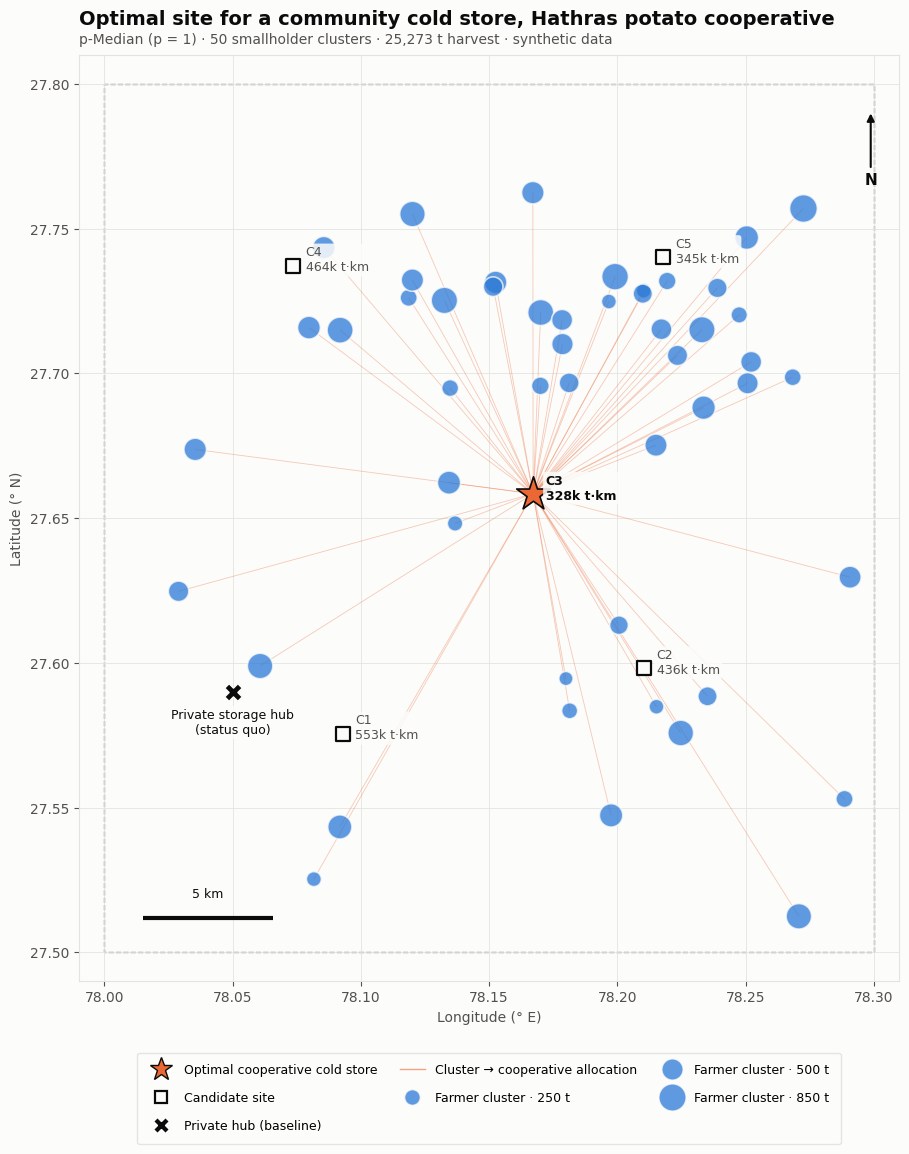

In [9]:
# --- Palette (validated categorical slots 1–2 + neutral ink) --------------
C_FARMER   = "#2a78d6"   # series-1 blue
C_OPTIMAL  = "#eb6834"   # series-2 orange
C_INK      = "#0b0b0b"
C_INK_2    = "#52514e"
C_MUTED    = "#8a8984"
C_GRID     = "#e4e3df"
C_SURFACE  = "#fcfcfb"

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.edgecolor": C_GRID, "axes.labelcolor": C_INK_2,
    "xtick.color": C_INK_2, "ytick.color": C_INK_2,
    "figure.facecolor": C_SURFACE, "axes.facecolor": C_SURFACE,
})


def size_for(volume_t, vmax):
    # Marker AREA proportional to volume (perceptually honest bubble sizing).
    return 20 + 380 * (np.asarray(volume_t) / vmax)


def add_scalebar(ax, km=5, lon0=None, lat0=None):
    # Draw a true-length scale bar using UTM-projected distance.
    lon0 = lon0 or LON_MIN + 0.015
    lat0 = lat0 or LAT_MIN + 0.012
    p0 = gpd.GeoSeries([Point(lon0, lat0)], crs=CRS_GEO).to_crs(CRS_METRIC).iloc[0]
    p1 = gpd.GeoSeries([Point(p0.x + km * 1000, p0.y)], crs=CRS_METRIC).to_crs(CRS_GEO).iloc[0]
    ax.plot([lon0, p1.x], [lat0, lat0], color=C_INK, lw=3, solid_capstyle="butt")
    ax.text((lon0 + p1.x) / 2, lat0 + 0.006, f"{km} km", ha="center", va="bottom", fontsize=9, color=C_INK)


def add_north_arrow(ax, x=0.965, y=0.94):
    ax.annotate("N", xy=(x, y), xytext=(x, y - 0.075), xycoords="axes fraction",
                ha="center", va="center", fontsize=11, fontweight="bold", color=C_INK,
                arrowprops=dict(arrowstyle="-|>", color=C_INK, lw=1.5))


def plot_site_map(farmers, candidates, private_hub, opt_j, candidate_eval, path=None):
    fig, ax = plt.subplots(figsize=(10, 11.5))
    vmax = farmers.volume_t.max()

    # Study-area frame
    study_area.boundary.plot(ax=ax, color=C_MUTED, lw=1, ls="--", zorder=0)

    # Allocation spokes: cluster -> optimal site
    opt_pt = candidates.geometry.iloc[opt_j]
    spokes = gpd.GeoSeries([LineString([p, opt_pt]) for p in farmers.geometry], crs=CRS_GEO)
    spokes.plot(ax=ax, color=C_OPTIMAL, lw=0.6, alpha=0.35, zorder=1)

    # Farmer clusters (white edge = 2px surface ring separating overlaps)
    ax.scatter(farmers.lon, farmers.lat, s=size_for(farmers.volume_t, vmax),
               color=C_FARMER, alpha=0.75, edgecolor=C_SURFACE, linewidth=1.2, zorder=3)

    # Candidate sites + labels with their burden
    tkm = candidate_eval.set_index("site_id").ton_km
    for j, row in candidates.iterrows():
        is_opt = j == opt_j
        if not is_opt:
            ax.scatter(row.lon, row.lat, marker="s", s=110, facecolor=C_SURFACE,
                       edgecolor=C_INK, linewidth=1.6, zorder=4)
        label = f"{row.site_id}\n{tkm[row.site_id]/1000:,.0f}k t·km"
        ax.annotate(label, (row.lon, row.lat), xytext=(9, -4), textcoords="offset points",
                    fontsize=9, color=C_INK if is_opt else C_INK_2,
                    fontweight="bold" if is_opt else "normal", zorder=6,
                    bbox=dict(boxstyle="round,pad=0.2", fc=C_SURFACE, ec="none", alpha=0.85))

    # Optimal site
    ax.scatter(opt_pt.x, opt_pt.y, marker="*", s=650, color=C_OPTIMAL,
               edgecolor=C_INK, linewidth=1.2, zorder=5)

    # Status-quo private hub
    hub = private_hub.iloc[0]
    ax.scatter(hub.lon, hub.lat, marker="X", s=160, color=C_INK, edgecolor=C_SURFACE, lw=1, zorder=5)
    ax.annotate("Private storage hub\n(status quo)", (hub.lon, hub.lat), xytext=(0, -12),
                textcoords="offset points", ha="center", va="top", fontsize=9, color=C_INK, zorder=6,
                bbox=dict(boxstyle="round,pad=0.2", fc=C_SURFACE, ec="none", alpha=0.85))

    # Cartographic furniture
    add_scalebar(ax, km=5)
    add_north_arrow(ax)
    ax.set_xlim(LON_MIN - 0.01, LON_MAX + 0.01)
    ax.set_ylim(LAT_MIN - 0.01, LAT_MAX + 0.01)
    ax.set_xlabel("Longitude (° E)")
    ax.set_ylabel("Latitude (° N)")
    ax.grid(color=C_GRID, lw=0.6)
    ax.set_axisbelow(True)

    # Legend: marker types + bubble-size key
    handles = [
        Line2D([], [], marker="*", ls="", ms=17, mfc=C_OPTIMAL, mec=C_INK, label="Optimal cooperative cold store"),
        Line2D([], [], marker="s", ls="", ms=9, mfc=C_SURFACE, mec=C_INK, mew=1.6, label="Candidate site"),
        Line2D([], [], marker="X", ls="", ms=11, mfc=C_INK, mec=C_SURFACE, label="Private hub (baseline)"),
        Line2D([], [], color=C_OPTIMAL, alpha=0.6, lw=1, label="Cluster → cooperative allocation"),
    ]
    for v in [250, 500, 850]:
        handles.append(Line2D([], [], marker="o", ls="", color=C_FARMER, alpha=0.75, mec=C_SURFACE,
                              ms=np.sqrt(size_for(v, vmax)), label=f"Farmer cluster · {v} t"))
    leg = ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.07), ncol=3,
                    frameon=True, fontsize=9, labelspacing=1.2, columnspacing=1.8, borderpad=0.9,
                    facecolor=C_SURFACE, edgecolor=C_GRID)
    leg.get_frame().set_alpha(0.95)

    ax.set_title("Optimal site for a community cold store, Hathras potato cooperative\n",
                 loc="left", fontsize=14, fontweight="bold", color=C_INK)
    ax.text(0, 1.012, f"p-Median (p = 1) · {len(farmers)} smallholder clusters · "
            f"{farmers.volume_t.sum():,.0f} t harvest · synthetic data",
            transform=ax.transAxes, fontsize=10, color=C_INK_2)

    fig.tight_layout()
    if path:
        fig.savefig(path, dpi=200, bbox_inches="tight")
    return fig, ax


fig, ax = plot_site_map(farmers, candidates, private_hub, opt_j, candidate_eval,
                        path=OUTPUT_DIR / "hathras_optimal_site_map.png")
plt.show()

### 5.2 Baseline vs. optimised cooperative placement
The report compares three scenarios on the same harvest:

1. **Status quo.** Every cluster hauls to the private hub.
2. **Naïve siting.** The cooperative picks a candidate without optimisation, scored as the *average* of the five candidates (the expected result of an arbitrary choice).
3. **Optimised.** The p-Median solution.

Rupee figures use the illustrative freight rate set in Section 2.1.

In [10]:
def scenario_metrics(dist_km: np.ndarray, weights_t: np.ndarray) -> dict:
    # Logistics KPIs for one assignment of clusters to a facility.
    tkm = float(dist_km @ weights_t)
    return {
        "ton_km": tkm,
        "transport_cost_inr": tkm * FREIGHT_INR_PER_TKM,
        "avg_haul_km_per_t": tkm / weights_t.sum(),
        "max_haul_km": float(dist_km.max()),
        "share_vol_within_10km_%": 100 * weights_t[dist_km <= 10].sum() / weights_t.sum(),
    }


d_opt = D[np.arange(len(farmers)), result["assign_idx"]]
naive = pd.DataFrame([scenario_metrics(D[:, j], w) for j in range(D.shape[1])]).mean().to_dict()

report = pd.DataFrame({
    "Status quo (private hub)": scenario_metrics(D_hub, w),
    "Naïve co-op site (avg.)": naive,
    f"Optimised co-op ({opt_site.site_id})": scenario_metrics(d_opt, w),
})

base = report.iloc[:, 0]
opt = report.iloc[:, -1]
saving_tkm = base.ton_km - opt.ton_km
saving_inr = base.transport_cost_inr - opt.transport_cost_inr
pct = 100 * saving_tkm / base.ton_km
per_household = saving_inr / farmers.households.sum()
per_ton = saving_inr / w.sum()
vs_naive = 100 * (naive["ton_km"] - opt.ton_km) / naive["ton_km"]

W = 70
print("=" * W)
print(" HATHRAS POTATO COOPERATIVE · COLD-STORAGE SITING REPORT".center(W))
print("=" * W)
print(f" Clusters: {len(farmers)}   Households: {farmers.households.sum():,}   "
      f"Harvest: {w.sum():,.0f} t   Freight: ₹{FREIGHT_INR_PER_TKM:.0f}/t·km")
print(f" Optimal site: {opt_site.site_id} @ {opt_site.lat:.5f}° N, {opt_site.lon:.5f}° E")
print("-" * W)
labels = {
    "ton_km": ("Total transport burden", "{:>14,.0f} t·km"),
    "transport_cost_inr": ("Seasonal transport cost", "{:>14,.0f} ₹"),
    "avg_haul_km_per_t": ("Avg. haul per ton", "{:>14.2f} km"),
    "max_haul_km": ("Longest haul (worst cluster)", "{:>14.2f} km"),
    "share_vol_within_10km_%": ("Harvest within 10 km", "{:>14.1f} %"),
}
for col in report.columns:
    print(f"\n ▸ {col}")
    for k, (name, fmt) in labels.items():
        print(f"     {name:<30}{fmt.format(report.loc[k, col])}")
print("\n" + "-" * W)
print(" IMPACT OF THE OPTIMISED COOPERATIVE FACILITY vs. STATUS QUO")
print(f"     Haulage avoided              {saving_tkm:>14,.0f} t·km   ({pct:.1f} % lower)")
print(f"     Transport cost saved         {saving_inr:>14,.0f} ₹ per season")
print(f"     ... per household            {per_household:>14,.0f} ₹ per season")
print(f"     ... per ton stored           {per_ton:>14,.0f} ₹/t")
print(f"     Gain from optimising vs. a naïve co-op site: {vs_naive:.1f} % fewer t·km")
print("=" * W)

report

        HATHRAS POTATO COOPERATIVE · COLD-STORAGE SITING REPORT       
 Clusters: 50   Households: 927   Harvest: 25,273 t   Freight: ₹12/t·km
 Optimal site: C3 @ 27.65846° N, 78.16716° E
----------------------------------------------------------------------

 ▸ Status quo (private hub)
     Total transport burden               598,364 t·km
     Seasonal transport cost            7,180,369 ₹
     Avg. haul per ton                      23.68 km
     Longest haul (worst cluster)           37.35 km
     Harvest within 10 km                     7.4 %

 ▸ Naïve co-op site (avg.)
     Total transport burden               425,137 t·km
     Seasonal transport cost            5,101,647 ₹
     Avg. haul per ton                      16.82 km
     Longest haul (worst cluster)           32.56 km
     Harvest within 10 km                    21.9 %

 ▸ Optimised co-op (C3)
     Total transport burden               327,740 t·km
     Seasonal transport cost            3,932,879 ₹
     Avg. haul per ton

,Status quo (private hub),Naïve co-op site (avg.),Optimised co-op (C3)
ton_km,"598,364.05","425,137.21","327,739.95"
transport_cost_inr,"7,180,368.62","5,101,646.55","3,932,879.45"
avg_haul_km_per_t,23.68,16.82,12.97
max_haul_km,37.35,32.56,24.90
share_vol_within_10km_%,7.40,21.94,23.53


### 5.3 Burden by site
The chart below shows the stakes of the siting decision. Each bar is the season's total haulage if the cooperative opened only that site, with the private hub shown for comparison.

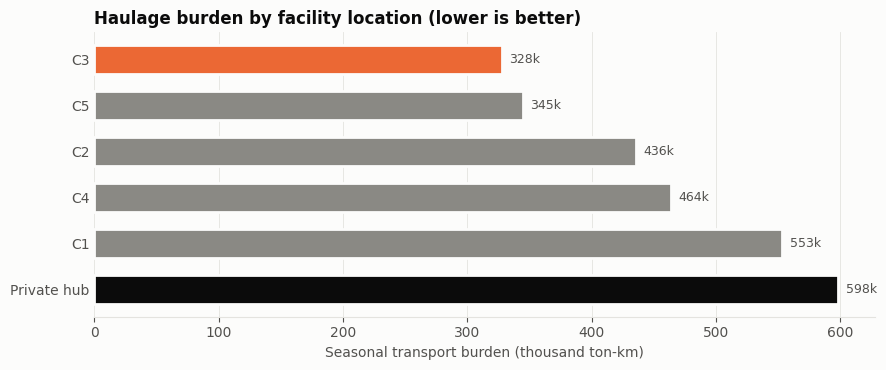

In [11]:
def plot_burden_bars(candidate_eval, hub_tkm, opt_site_id, path=None):
    df = candidate_eval[["site_id", "ton_km"]].copy()
    df = pd.concat([df, pd.DataFrame({"site_id": ["Private hub"], "ton_km": [hub_tkm]})])
    df = df.sort_values("ton_km", ascending=True).reset_index(drop=True)
    colors = [C_OPTIMAL if s == opt_site_id else (C_INK if s == "Private hub" else C_MUTED)
              for s in df.site_id]

    fig, ax = plt.subplots(figsize=(9, 3.8))
    bars = ax.barh(df.site_id, df.ton_km / 1000, color=colors, height=0.62,
                   edgecolor=C_SURFACE, linewidth=2)
    for b, v in zip(bars, df.ton_km):
        ax.text(b.get_width() + df.ton_km.max() / 1000 * 0.01, b.get_y() + b.get_height() / 2,
                f"{v/1000:,.0f}k", va="center", fontsize=9, color=C_INK_2)
    ax.invert_yaxis()
    ax.set_xlabel("Seasonal transport burden (thousand ton-km)")
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.tick_params(axis="y", length=0)
    ax.grid(axis="x", color=C_GRID, lw=0.6)
    ax.set_axisbelow(True)
    ax.set_title("Haulage burden by facility location (lower is better)",
                 loc="left", fontsize=12, fontweight="bold", color=C_INK)
    fig.tight_layout()
    if path:
        fig.savefig(path, dpi=200, bbox_inches="tight")
    return fig, ax


plot_burden_bars(candidate_eval, base["ton_km"], opt_site.site_id,
                 path=OUTPUT_DIR / "hathras_burden_by_site.png")
plt.show()

### 5.4 Sensitivity: would a second facility pay off?
A cooperative usually starts with one store and expands later. Re-solving for *p* = 1…3 shows the **diminishing marginal return** of each extra facility. The treasurer can weigh the ton-km saved against the capital cost of another building.

In [12]:
rows = []
for p in range(1, 4):
    r = solve_p_median(D, w, p=p, cluster_ids=farmers.cluster_id.tolist(),
                       site_ids=candidates.site_id.tolist())
    rows.append({"p": p, "open_sites": ", ".join(r["open_sites"]),
                 "ton_km": r["objective_tkm"],
                 "cost_inr": r["objective_tkm"] * FREIGHT_INR_PER_TKM})
sens = pd.DataFrame(rows)
sens["marginal_saving_inr"] = (-sens.cost_inr.diff()).fillna(base.transport_cost_inr - sens.cost_inr.iloc[0])
sens["vs_status_quo_%"] = 100 * (1 - sens.ton_km / base.ton_km)
sens

,p,open_sites,ton_km,cost_inr,marginal_saving_inr,vs_status_quo_%
0,1,C3,"327,739.95","3,932,879.45","3,247,489.17",45.23
1,2,"C2, C5","240,659.24","2,887,910.90","1,044,968.56",59.78
2,3,"C2, C4, C5","188,033.52","2,256,402.21","631,508.68",68.58


### 5.5 Export
The results are written to `outputs/` so they can feed a GIS (GeoPackage), a spreadsheet (CSV) or a report (PNG).

In [13]:
alloc = farmers.copy()
alloc["assigned_site"] = candidates.site_id.iloc[result["assign_idx"]].to_numpy()
alloc["haul_km"] = d_opt
alloc["ton_km"] = d_opt * w
alloc["baseline_haul_km"] = D_hub

alloc.to_file(OUTPUT_DIR / "hathras_coldstore.gpkg", layer="farmer_clusters", driver="GPKG")
candidates.merge(candidate_eval[["site_id", "ton_km"]], on="site_id") \
    .assign(selected=lambda g: g.site_id == opt_site.site_id) \
    .to_file(OUTPUT_DIR / "hathras_coldstore.gpkg", layer="candidate_sites", driver="GPKG")
alloc.drop(columns="geometry").to_csv(OUTPUT_DIR / "cluster_allocation.csv", index=False)
report.to_csv(OUTPUT_DIR / "scenario_report.csv")

for f in sorted(OUTPUT_DIR.iterdir()):
    print(f"  {f}  ({f.stat().st_size/1024:,.1f} KB)")

  outputs/cluster_allocation.csv  (8.0 KB)
  outputs/hathras_burden_by_site.png  (53.0 KB)
  outputs/hathras_coldstore.gpkg  (124.0 KB)
  outputs/hathras_optimal_site_map.png  (421.5 KB)
  outputs/scenario_report.csv  (0.4 KB)


---
## 6. Interpretation, Limitations & Next Steps

**What the result says.** For this synthetic district, putting the cooperative cold store at the optimised site (rather than relying on the private hub) cuts the farmers' combined haulage substantially. It also brings far more of the harvest within a short tractor-trolley trip. The site sits near the **volume-weighted centre** of production, not the geographic centre: large clusters pull it toward them.

**Why it matters for the cooperative model.**
* *Logistics:* shorter hauls let the cooperative aggregate small lots into full truckloads at the store and then market them collectively.
* *Market power:* a member-owned facility within reach gives farmers an alternative to private storage, which weakens the rent-setting and distressed-sale leverage described in Section 1.
* *Capital:* recurring transport savings are a quantifiable benefit that can back a loan application or grant proposal (NABARD, the Mission for Integrated Development of Horticulture cold-chain subsidy, or the Agriculture Infrastructure Fund).

**Limitations.**
| Assumption | Real-world refinement |
|---|---|
| Synthetic clusters and volumes | Field survey / Farmer Producer Organisation (FPO) membership rolls, with GPS points |
| Straight-line × 1.3 circuity | OSM road-network distances (`osmnx`), seasonal road quality |
| Uncapacitated facility | Add $\sum_i w_i x_{ij} \le Q_j y_j$ for chamber capacity $Q_j$ (capacitated p-Median) |
| Flat freight rate | Load-dependent rates (tractor vs. truck), fuel-price scenarios |
| Transport cost only | Add fixed cost $f_j y_j$ and solve as an Uncapacitated Facility Location Problem (UFLP) to choose *p* endogenously |
| Single season | Multi-year demand growth; robust or stochastic siting |

---
*Methods: Hakimi (1964), Operations Research 12(3); ReVelle & Swain (1970), Geographical Analysis 2(1). Solvers: HiGHS / COIN-OR CBC via PuLP.*